# The 4x zoom dataset

This walkthrough illustrates the proposed training task using real CUDA renders.
It does **not** generate the 10,000-pair training dataset.

Prerequisites: the repository notebook dependencies and an NVIDIA CUDA GPU.
Run all cells in order. We will inspect parent/child alignment, compare enlarged
crops with exact child renders, and check sensitivity to the iteration budget.

In [1]:
from pathlib import Path
import sys
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "model.py").exists() and (p / "mandelbrot.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
assert torch.cuda.is_available(), "These notebooks use the CUDA renderer."
torch.manual_seed(20261016)
print(torch.cuda.get_device_name())
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11})

NVIDIA GeForce RTX 4090


In [2]:
from mandelbrot import ColorRenderer, View

SIZE = 128
AA = 8  # 8x8 subpixel samples (64 per pixel), averaged after coloring.
renderer = ColorRenderer(SIZE * AA, SIZE * AA)

def render_rgb(view):
    # ColorRenderer reuses buffers: clone before retaining a render.
    rgb = renderer.render(view).clone().permute(2, 0, 1)[None]
    return F.avg_pool2d(rgb, AA)

def zoom_pair(parent_view, left, top):
    side = SIZE // 4
    assert 0 <= left <= SIZE-side and 0 <= top <= SIZE-side
    parent = render_rgb(parent_view)
    crop = parent[:, :, top:top+side, left:left+side]
    coarse = F.interpolate(crop, size=(SIZE, SIZE), mode="bilinear", align_corners=False)
    # Positive image y points down; positive imaginary coordinates point up.
    offset = complex(left + side/2 - SIZE/2, SIZE/2 - top - side/2)
    center = parent_view.center + offset * parent_view.span / SIZE
    child_view = View(center=center, span=parent_view.span / 4,
                      iterations=parent_view.iterations)
    target = render_rgb(child_view)
    return parent, coarse, target, child_view

def show_rgb(axis, image, title):
    axis.imshow(image[0].detach().float().cpu().permute(1, 2, 0).clamp(0, 1), interpolation="nearest")
    axis.set_title(title)
    axis.axis("off")

Warp 1.18.0 initialized:
   CUDA Toolkit 13.4, Driver 13.0
   Devices:
     "cpu"      : "CPU"
     "cuda:0"   : "NVIDIA GeForce RTX 4090" (24 GiB, sm_89, mempool enabled)
   Kernel cache:
     /home/blacknoir/.cache/warp/1.18.0


## Parent → enlarged crop → detailed target

A 4x **linear** zoom divides the viewport span by four. At 128x128, the selected
crop contains 32x32 parent pixels. Bilinear interpolation enlarges that crop;
the target is a separate render of the same region. The rectangle marks the
crop in parent pixel coordinates. All panels use the renderer's fixed palette.

Module mandelbrot 617f2d0 load on device 'cuda:0' took 0.34 ms  (cached)


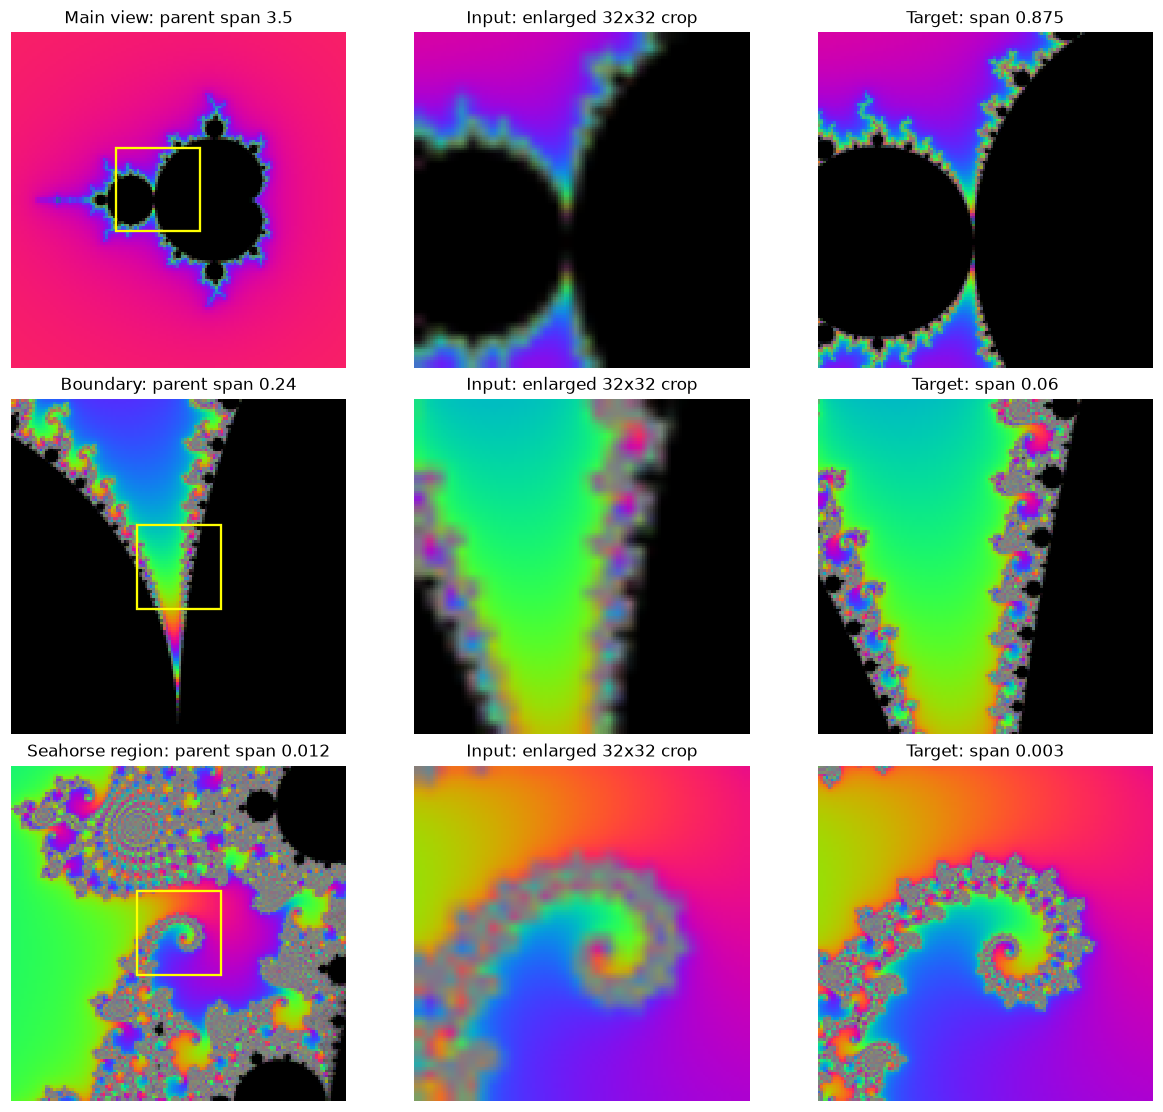

In [3]:
from matplotlib.patches import Rectangle

examples = [
    ("Main view", View(center=-.5+0j, span=3.5, iterations=4096), 40, 44),
    ("Boundary", View(center=-.75+.12j, span=.24, iterations=4096), 48, 48),
    ("Seahorse region", View(center=-.7435+.1314j, span=.012, iterations=4096), 48, 48),
]
fig, axes = plt.subplots(len(examples), 3, figsize=(11, 10), constrained_layout=True)
for row, (label, view, left, top) in enumerate(examples):
    parent, coarse, target, child = zoom_pair(view, left, top)
    show_rgb(axes[row, 0], parent, f"{label}: parent span {view.span:g}")
    axes[row, 0].add_patch(Rectangle((left-.5, top-.5), SIZE//4, SIZE//4,
                                  fill=False, edgecolor="yellow", linewidth=1.5))
    show_rgb(axes[row, 1], coarse, "Input: enlarged 32x32 crop")
    show_rgb(axes[row, 2], target, f"Target: span {child.span:g}")
plt.show()

## Check rendering sensitivity

Compare a child at 4096 and 8192 iterations. A small pixel difference is useful
evidence for this example, not proof of mathematical membership or convergence
for all views. Colors can change when an orbit escapes after the lower budget.

Iteration-budget RGB MAE: 4.75532e-07


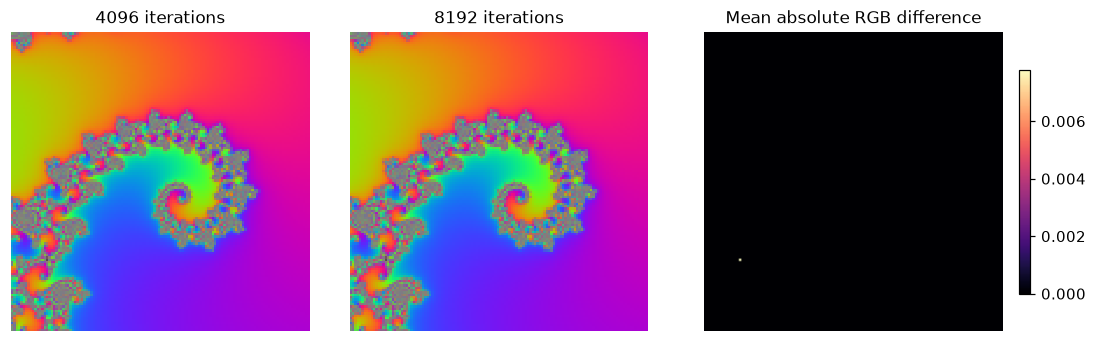

In [4]:
_, y, x, child = zoom_pair(examples[-1][1], 48, 48)
higher = render_rgb(View(center=child.center, span=child.span, iterations=8192))
difference = (higher - x).abs().mean(dim=1)[0]
print(f"Iteration-budget RGB MAE: {difference.mean().item():.6g}")
fig, axes = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)
show_rgb(axes[0], x, "4096 iterations")
show_rgb(axes[1], higher, "8192 iterations")
plot = axes[2].imshow(difference.cpu(), cmap="magma", vmin=0)
axes[2].set_title("Mean absolute RGB difference")
axes[2].axis("off")
fig.colorbar(plot, ax=axes[2], shrink=.75)
plt.show()

## Antialiasing: sample the fractal before averaging

The examples above use **8x8 samples per output pixel**, up from the original
2x2 notebook setup. Each sample is colored first, then RGB values are averaged.
Averaging escape times before applying the palette would give a different result.

Below, render the same 128x128 child at 1x1, 2x2, 4x4, 8x8, and 16x16 sampling.
The 16x16 image is a higher-sample comparison, **not exact ground truth**.
The plot uses nearest-neighbor display so image interpolation does not hide
aliasing. More samples reduce spatial aliasing; iteration-budget errors need
the separate check above. The intentionally blurred input crop remains blurred.

 1x1 : RGB MAE against 16x16 = 0.053756
 2x2 : RGB MAE against 16x16 = 0.024256
 4x4 : RGB MAE against 16x16 = 0.011507
 8x8 : RGB MAE against 16x16 = 0.005728
16x16: RGB MAE against 16x16 = 0.000000


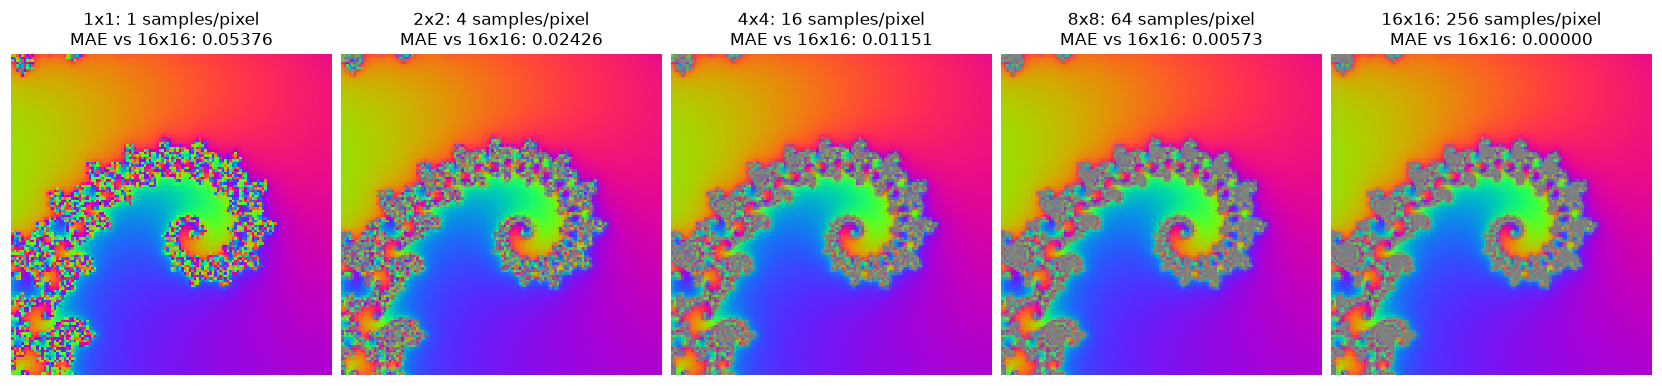

In [5]:
aa_view = View(center=child.center, span=child.span, iterations=8192)
aa_images = {}
for side in (1, 2, 4, 8, 16):
    aa_renderer = ColorRenderer(SIZE * side, SIZE * side)
    raw = aa_renderer.render(aa_view).clone().permute(2, 0, 1)[None]
    aa_images[side] = F.avg_pool2d(raw, side)
    del raw, aa_renderer

fig, axes = plt.subplots(1, 5, figsize=(15, 3.5), constrained_layout=True)
reference = aa_images[16]
for axis, (side, image) in zip(axes, aa_images.items()):
    mae = (image-reference).abs().mean().item()
    show_rgb(axis, image, f"{side}x{side}: {side*side} samples/pixel\nMAE vs 16x16: {mae:.5f}")
    print(f"{side:2d}x{side:<2d}: RGB MAE against 16x16 = {mae:.6f}")
plt.show()

## Storage and split design

`train.py` expects `inputs` and `targets` tensors of shape `[N,3,128,128]`,
floating point in `[0,1]`, in each split's `.pt` file. The training loader maps
both to `[-1,1]`. Keep viewport settings and branch identifiers with the dataset.

Planned collection: boundary-guided branching, coverage across zoom depths,
fixed coloring, and validation on held-out branches. These three hand-picked
examples illustrate the geometry; they do not establish dataset coverage.

**Try:** change the last crop's `left` to 40. Its real-coordinate displacement
should be `-8 * parent_span / 128`; the child span remains unchanged.

In [6]:
view = examples[-1][1]
old_center = view.center  # The (48,48) crop is centered.
_, _, _, shifted = zoom_pair(view, 40, 48)
expected = old_center - 8 * view.span / SIZE
assert abs(shifted.center - expected) < 1e-14
assert shifted.span == view.span / 4
print("Movable crop alignment verified.")

Movable crop alignment verified.
